<a href="https://colab.research.google.com/github/Shinki0202/kadai/blob/main/GitHub_Test_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

T4 GPUが利用可能かどうか確認

In [1]:
# 1. GPU (T4等) が利用可能か自動チェック
import sys
import torch

if torch.cuda.is_available():
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    print(f"✅ GPUが有効です: {gpu_name}")
else:
    # CPUの場合は警告を出す
    print("⚠️ 警告: GPUが有効になっていません！")
    print("Colabの上部メニュー [ランタイム] -> [ランタイムのタイプを変更] から『T4 GPU』を選択してください。")

✅ GPUが有効です: Tesla T4


GitHubから画像データを読み込む

画像のサイズ (幅, 高さ)ピクセル: (576, 1024)


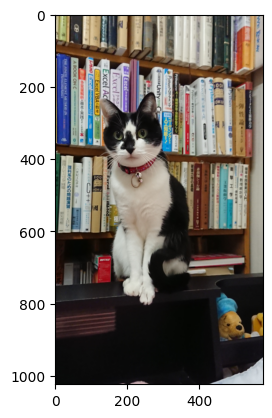

In [2]:
from PIL import Image, ImageOps
from io import BytesIO
import requests
from matplotlib import pyplot as plt

# GitHub上の画像URL
image_github = "https://github.com/Taka-Lab-Python/Human_AI_Exercises/blob/main/cat2.png"
image_url = image_github.replace(
"github.com", "raw.githubusercontent.com").replace("/blob/", "/")

# GitHubから画像を取得
response = requests.get(image_url, timeout=30)
response.raise_for_status()

# PIL画像に変換
img_pil_1 = Image.open(BytesIO(response.content))
img_pil_1 = ImageOps.exif_transpose(img_pil_1)
img_pil_1 = img_pil_1.convert("RGB")
img_pil_1.thumbnail((1024, 1024))  # 大きな写真は縮小してメモリを節約


print(f"画像のサイズ (幅, 高さ)ピクセル: {img_pil_1.size}")
plt.imshow(img_pil_1)  # 画像を描かせる
plt.show()

セル1：ライブラリのインストール

In [3]:
# セル1：ライブラリのインストール
!pip install -q -U "transformers>=4.57.0" accelerate

In [4]:
#セル2：モジュールのインポート(重要)
import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

In [7]:
# セル3：モデルのダウンロード・読み込み
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"
# Hugging FaceからColabにダウンロード
model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map="cuda",
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model.eval()
print("モデルの読み込み完了")

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

モデルの読み込み完了


Saving 134248468207379429.jpg to 134248468207379429.jpg
画像のサイズ (幅, 高さ)ピクセル: (1024, 576)


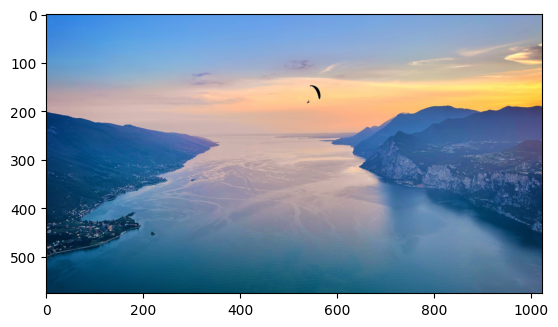

In [8]:
# セル4：写真のアップロード
from google.colab import files
from PIL import Image, ImageOps
uploaded = files.upload()
image_path = next(iter(uploaded))
img_pil = Image.open(image_path)
img_pil = ImageOps.exif_transpose(img_pil) # スマホ写真の向きを補正
img_pil = img_pil.convert("RGB")
img_pil.thumbnail((1024, 1024)) # 大きな写真は縮小してメモリを節約
print(f"画像のサイズ (幅, 高さ)ピクセル: {img_pil.size}")
plt.imshow(img_pil) # 画像を描かせる
plt.show()

In [19]:
# セル5：プロンプトを入力して実行
prompt = "この写真に何が写っているか、背景に何が写っているか、日本語で説明してください。"
messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": img_pil_1},
                {"type": "text", "text": prompt},
            ],
        }
]
inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
).to(model.device)

In [21]:
# 推論モード：学習用の計算（勾配）を記録しないため、メモリ節約と高速化になる
with torch.inference_mode():
    generated_ids = model.generate(**inputs, max_new_tokens=500)

# generated_ids には「入力（プロンプト）＋回答」がつながって入っている
# 入力したトークン数を数える
input_length = inputs["input_ids"].shape[1]

# 入力の長さより後ろ＝モデルの回答部分だけを取り出す（画像は1枚なので [0]）
answer_ids = generated_ids[0][input_length:]

# トークン番号を日本語の文章に戻す（特殊トークンは除く）
answer = processor.decode(answer_ids, skip_special_tokens=True)
print(answer)

この写真は、猫が書棚の上に座っている様子を捉えたものです。背景には、多くの本が並んでおり、その中には「Excel」や「Python」などのプログラミング関連の書籍が含まれています。また、右下には小さなぬいぐるみが見えます。
